# Weight-space programming: Astra vs Sol on Swedish adjective inflection

Can a frontier model repair one learned grammatical failure by editing weights, without gradient descent, and without spoiling the rest of the paradigm?

Phase 1 trained the classifier, selected the lesion, and compared local repairs. Phase 2 then asked Sol and Astra for one edit each. A rerun loads those saved responses and does not call the API again. The research note is `RESEARCH_NOTE.md`.

The network is a small classifier trained from scratch. It is not a Swedish language model, and a later edit would not show that the same method improves a pretrained model.


## 1. Run the local experiment

Training, corruption search, baselines, the permutation check, and the mocked budget tests all live in `src/`. The saved Phase 1 artifacts are frozen, so this cell loads them.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src" / "pipeline.py").exists():
    raise RuntimeError("Run this notebook from astra_weight_edit so src/ is on the path.")
sys.path.insert(0, str(ROOT))

from src.pipeline import run_phase1, run_phase2

report = run_phase1(ROOT)
print(report["status"])
print(
    f"parameters={report['architecture']['n_parameters']}  "
    f"epochs={report['epochs']}  train_seconds={report['training_seconds']:.2f}"
)
print(
    f"test original={report['original_test']['example_acc']:.3f}  "
    f"prompt_tokens={report['one_shot_input_tokens']}  "
    f"worst_case_pair=${report['worst_case_primary_pair_usd']:.2f}"
)


Phase 1 artifacts are frozen. Loading the saved summary and not retraining.
phase1_complete_api_not_called
parameters=4425  epochs=180  train_seconds=0.40
test original=1.000  prompt_tokens=23236  worst_case_pair=$0.58


## 2. The grammatical task

Each row is one stem in one cell of gender, number, and definiteness. The label is an exponent (`NEUT_T`, `NEUT_TT`, `WEAK_DROP_E`, `LILLA`, …), and the surface form is a deterministic spelling of that exponent. Held-out stems share a class with training stems but not an input vector: sixteen small stem bits distinguish them, and the label ignores those bits.


In [2]:
import pandas as pd

dataset = pd.read_csv(ROOT / "results" / "dataset.csv")
examples = [
    "en stor bil", "ett stort hus", "det stora huset", "stora bilar",
    "ett nytt hus", "ett rött hus", "ett vitt hus", "de nya bilarna",
    "ett vackert hus", "vackra bilar", "ett gammalt hus", "den gamla bilen",
    "ett moget hus", "den mogna bilen", "ett litet hus", "den lilla bilen",
    "små bilar", "de små husen", "ett bra hus", "den bra bilen",
]
show = dataset[dataset["phrase"].isin(examples)][
    ["phrase", "lexical_class", "exponent", "split"]
].drop_duplicates("phrase")
print(f"{dataset['stem'].nunique()} stems, {len(dataset)} rows, {dataset['exponent'].nunique()} exponents")
print("Hand-checked forms in the grammar module: 90")
show.sort_values("phrase")


96 stems, 768 rows, 9 exponents
Hand-checked forms in the grammar module: 90


,phrase,lexical_class,exponent,split
315,de nya bilarna,geminating,WEAK_A,train
767,de små husen,liten,SMA,inlexicon
681,den bra bilen,invariant,BASE,dev_diag
553,den gamla bilen,syncopating,WEAK_DROP_E,train
761,den lilla bilen,liten,LILLA,inlexicon
585,den mogna bilen,ends_en,WEAK_NA,train
5,det stora huset,regular,WEAK_A,train
0,en stor bil,regular,BASE,train
684,ett bra hus,invariant,BASE,dev_diag
556,ett gammalt hus,syncopating,NEUT_T,train


## 3. Training

The smallest width that reached the development criterion was 48. Widths 32 and 40 did not. Rounding every weight to three decimals, which is how the checkpoint is shown in a prompt, left test accuracy at 100%.


hidden search:
  hidden=32  params=2441  dev=0.553  accepted=False
  hidden=40  params=3369  dev=0.220  accepted=False
  hidden=48  params=4425  dev=1.000  accepted=True
quantized decimals: 3
serialization round-trip max abs error: 0.0


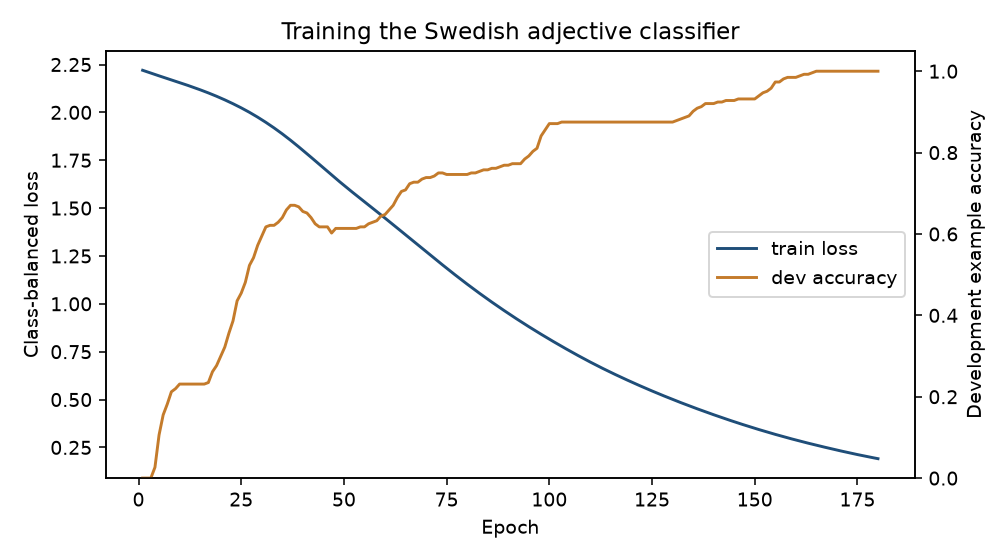

In [3]:
from IPython.display import Image, display

print("hidden search:")
for row in report["hidden_search"]:
    print(
        f"  hidden={row['hidden']:2d}  params={row['n_parameters']:4d}  "
        f"dev={row['dev_example_acc']:.3f}  accepted={row['accepted']}"
    )
print(f"quantized decimals: {report['quantize_decimals']}")
print(f"serialization round-trip max abs error: {report['serialization_roundtrip_max_abs']}")
display(Image(filename=str(ROOT / "results" / "figures" / "training_curve.png")))


## 4. Corruption

Protocol 1 lesions that stayed selective were undone by refitting the last layer: the exponent was still linearly decodable. The lesion kept here copies the first-layer uter gender column onto the neuter column. Neuter and uter phrases with the same stem then share a hidden state. Plural and definite labels already ignore gender, so those cells stay correct. Neuter singular indefinite, the cell where gender changes the exponent, is predicted as the uter base.

The development gate, not the test set, accepted the lesion. Test numbers are computed after that choice.


In [4]:
import pandas as pd

gate = pd.read_json(ROOT / "results" / "corruption_gate.json")
cols = [
    "candidate_index", "family", "corrupted_target", "bias_target", "bias_solves",
    "last_target", "last_solves", "gradient_target", "gradient_gain", "passed",
]
print(
    f"candidates={report['corruption']['n_candidates']}  "
    f"passed filter={report['corruption']['n_filter_passed']}  "
    f"gated={report['corruption']['n_gated']}"
)
print("selected:", report["corruption"]["family"], "index", report["corruption"]["selected_index"])
gate[cols]


candidates=85  passed filter=14  gated=8
selected: gender_column_copy index 84


,candidate_index,family,corrupted_target,bias_target,bias_solves,last_target,last_solves,gradient_target,gradient_gain,passed
0,40,column_scale,0.357143,0.928571,True,1.000000,True,1.000000,0.642857,False
1,30,column_scale,0.500000,1.000000,True,1.000000,True,0.857143,0.357143,False
2,33,column_scale,0.500000,1.000000,True,1.000000,True,1.000000,0.500000,False
3,79,stem_threshold,0.428571,0.857143,False,1.000000,True,1.000000,0.571429,False
4,42,column_noise,0.285714,0.785714,False,1.000000,True,0.857143,0.571429,False
5,37,column_scale,0.571429,1.000000,True,1.000000,True,1.000000,0.428571,False
6,51,column_noise,0.571429,0.714286,False,1.000000,True,0.928571,0.357143,False
7,84,gender_column_copy,0.000000,0.071429,False,0.428571,False,0.928571,0.928571,True


## 5. Did the intact network learn, and is the repair nontrivial?

Test stems were not used to train, to choose the lesion, or to fit a repair. Target accuracy is the strong-neuter cell (15 held-out stems). Non-target accuracy is every other test row.


,method,target_acc,nontarget_acc,example_acc,n_changed,l2,api_cost_usd
0,original,1.000,1.000,1.00,0.0,0.000,0.0
1,corrupted,0.000,1.000,0.89,0.0,0.000,0.0
2,output_bias,0.200,0.975,0.89,9.0,2.074,0.0
3,last_layer,0.533,0.934,0.89,378.0,12.503,0.0
4,gradient,1.000,1.000,1.00,40.0,6.081,0.0
5,random_mean,0.000,1.000,0.89,40.0,1.590,0.0


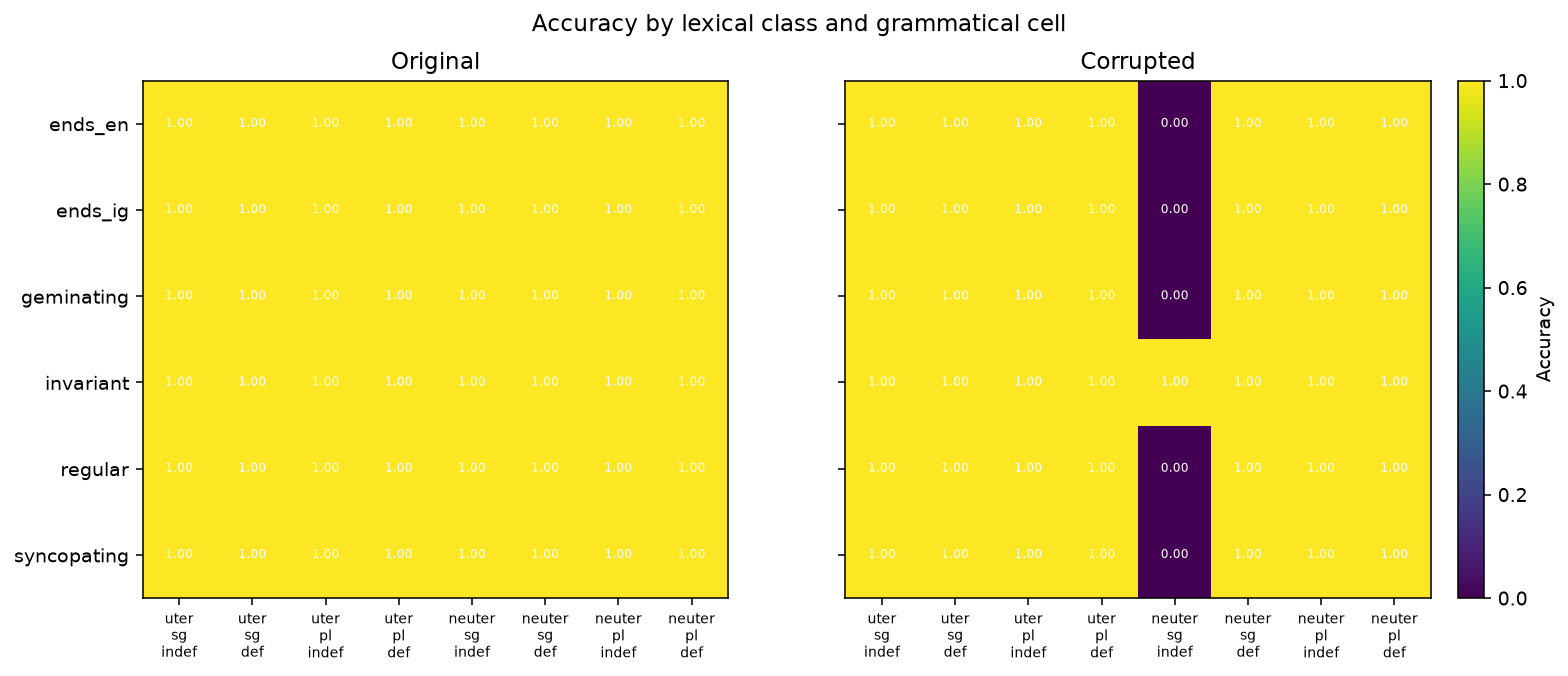

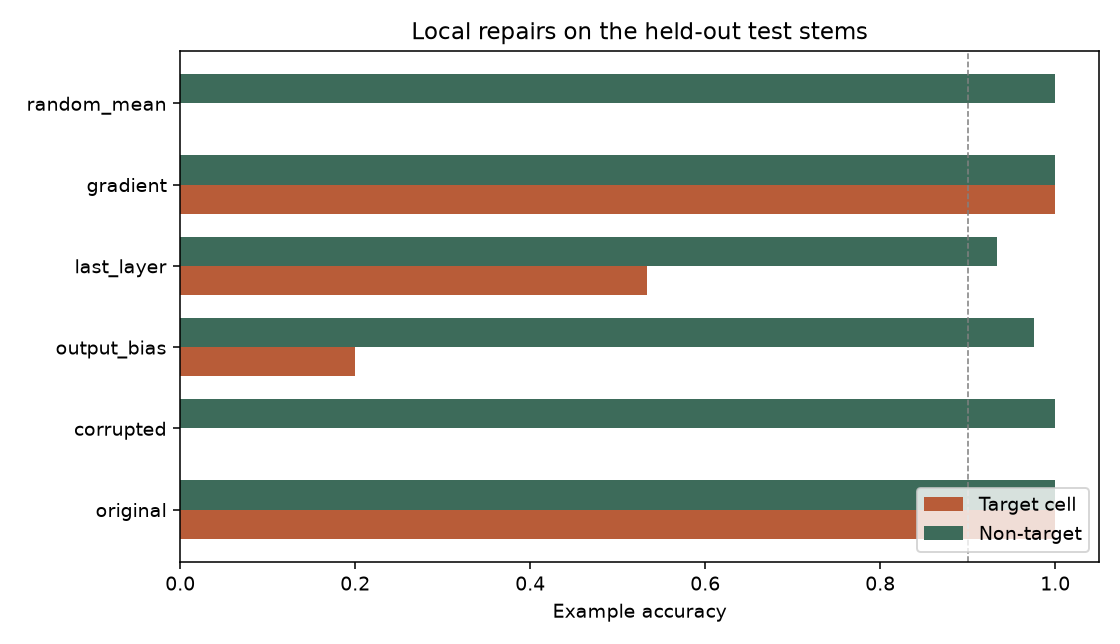

hidden-permutation max |logit| change: 2.384e-06


In [5]:
import pandas as pd
from IPython.display import Image, display

metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
display(metrics.round(3))
display(Image(filename=str(ROOT / "results" / "figures" / "accuracy_heatmap_test.png")))
display(Image(filename=str(ROOT / "results" / "figures" / "baseline_comparison.png")))
print(f"hidden-permutation max |logit| change: {report['permutation_max_abs_logit_diff']:.3e}")


## 6. One-shot results

The one-shot prompt contains the architecture, the feature index, the corrupted weights at three decimals, and the diagnostic rows. It does not contain the original weights, the column-copy recipe, gradients, or test labels. The reservation below assumes no cache discount and bills the full 6,000-token output cap, reasoning included.

The one-shot calls have already been made. This cell reloads them. `api_enabled` stays false, so a rerun cannot spend more.


,call,model,raw_input_tokens,reserved_input_tokens,worst_case_usd
0,sol_one_shot,gpt-6.2-sol,23236,27884,0.116
1,astra_one_shot,gpt-6.2-astra,23236,27884,0.463
2,sol_feedback,gpt-6.2-sol,25505,30606,0.121
3,astra_feedback,gpt-6.2-astra,25505,30606,0.485
4,sol_permuted,gpt-6.2-sol,23236,27884,0.116
5,astra_permuted,gpt-6.2-astra,23236,27884,0.463


worst-case one-shot pair: $0.58
worst-case all six calls: $1.76
budget: $5.00  sufficient=True
budget self-test: over-budget call rejected; uncertain call halts later calls; corrupt cumulative total is rejected; api_enabled false blocks the client; env loader reads a local key without printing it; edit validator accepts a sparse add and rejects an unknown tensor; weight serialization roundtrips


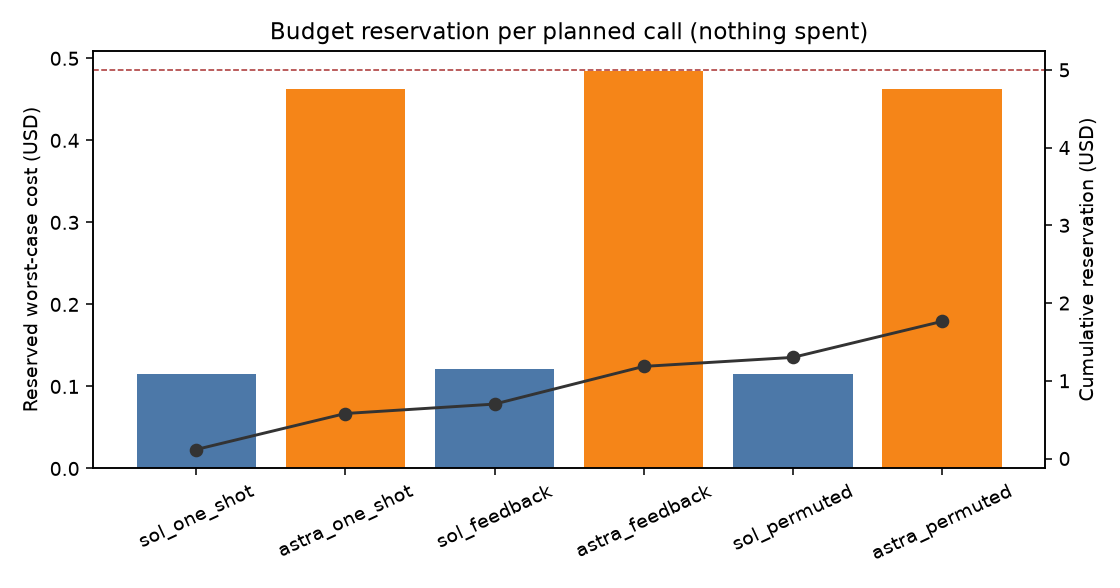

gpt-6.2-sol: loaded saved response resp_094d235e495f8de1016afe1f1e3aa087d2b15d7b5e3c6fb488. No new API call.
gpt-6.2-astra: loaded saved response resp_085490cd450b3ac6016afe1f79266887d2b0c9df5cf0885665. No new API call.


,method,diagnosis,target_acc,nontarget_acc,n_changed,api_cost_usd,category
0,Corrupted baseline,—,0.000000,1.000000,0,0.000000,NaN
1,Duplicate-column diagnostic,exact fc1 gender-column copy,NaN,NaN,0,0.000000,NaN
2,Random edits,—,0.000000,1.000000,40,0.000000,NaN
3,Output-bias repair,—,0.200000,0.975207,9,0.000000,NaN
4,Last-layer repair,—,0.533333,0.933884,378,0.000000,NaN
5,Gradient repair,—,1.000000,1.000000,40,0.000000,NaN
6,gpt-6.2-sol,no proposal; output cap spent on reasoning,0.000000,1.000000,0,0.107342,no_useful_repair
7,gpt-6.2-astra,duplicated fc1 gender columns,0.733333,1.000000,11,0.269768,selective_partial_repair


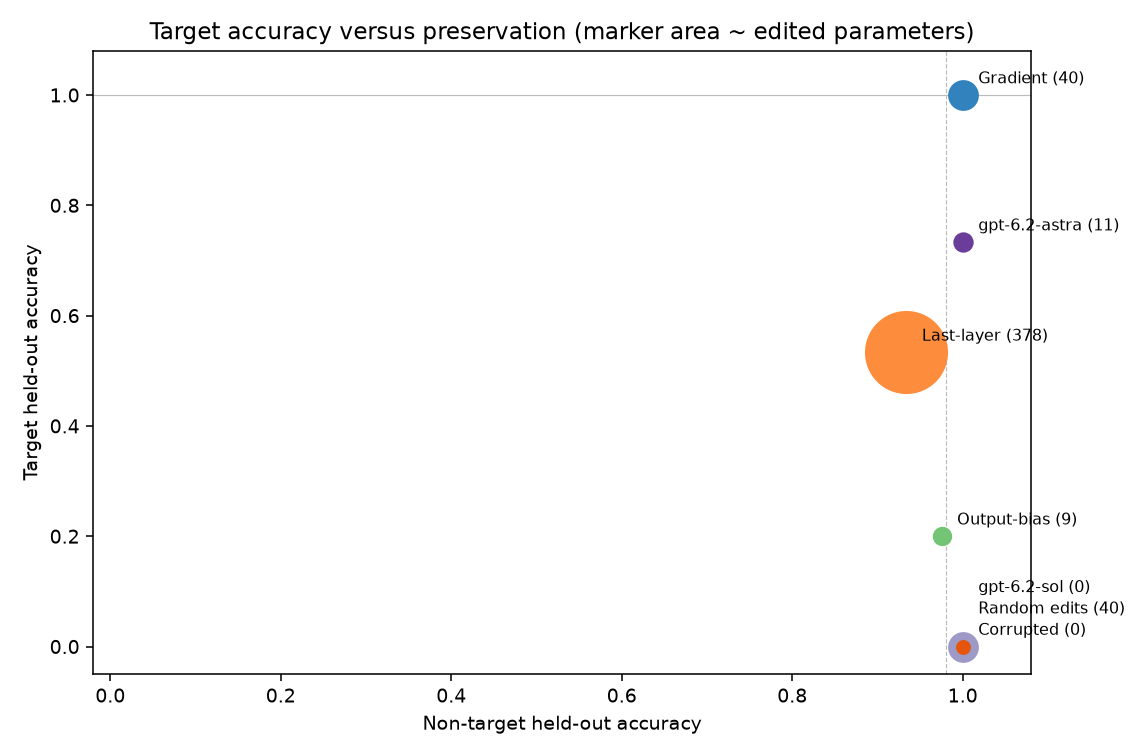

status=finished calls=2 spent=$0.786873 remaining=$4.213127


In [6]:
import pandas as pd
from IPython.display import Image, display

costs = pd.DataFrame(report["planned_calls"])
display(costs[["call", "model", "raw_input_tokens", "reserved_input_tokens", "worst_case_usd"]].round(3))
print(f"worst-case one-shot pair: ${report['worst_case_primary_pair_usd']:.2f}")
print(f"worst-case all six calls: ${report['worst_case_all_six_usd']:.2f}")
print(f"budget: ${report['budget_usd']:.2f}  sufficient={report['budget_sufficient_for_six']}")
print("budget self-test:", "; ".join(report["budget_self_test"]))
display(Image(filename=str(ROOT / "results" / "figures" / "api_cost_reservation.png")))

phase2 = run_phase2(ROOT)
comparison = pd.read_csv(ROOT / "results" / "phase2_comparison.csv")
display(comparison)
display(Image(filename=str(ROOT / "results" / "figures" / "phase2_comparison.png")))
print(
    f"status={phase2['status']} calls={phase2['calls']} "
    f"spent=${phase2['spent_usd']:.6f} remaining=${phase2['remaining_usd']:.6f}"
)
assert phase2["calls"] == 2
assert report["api_enabled"] is False


## 7. Follow-up

The gradient update was scaled to the L2 cap of 6. Astra's saved edit was transferred onto the permuted checkpoint. Two further calls, Astra on the permuted weights and Sol with a 12,000-token cap, are already saved. This cell only reloads them. The write-up is 
indings.md.

,method,target_accuracy,nontarget_accuracy,parameters,l2_norm,api_cost_usd
0,Corrupted model,0/15,121/121,0,0.000000,0.000000
1,Original gradient repair,15/15,121/121,40,6.081178,0.000000
2,Scaled gradient repair,15/15,121/121,40,6.000000,0.000000
3,Duplicate-column optimizer,15/15,121/121,40,4.053260,0.000000
4,Astra original,11/15,121/121,11,5.910087,0.269768
5,Astra edit transferred,11/15,121/121,11,5.910087,0.000000
6,Astra permuted attempt,11/15,121/121,23,5.940273,0.328360
7,Sol original attempt,no proposal,121/121,0,0.000000,0.107342
8,Sol extended attempt,15/15,121/121,28,5.976430,0.081403


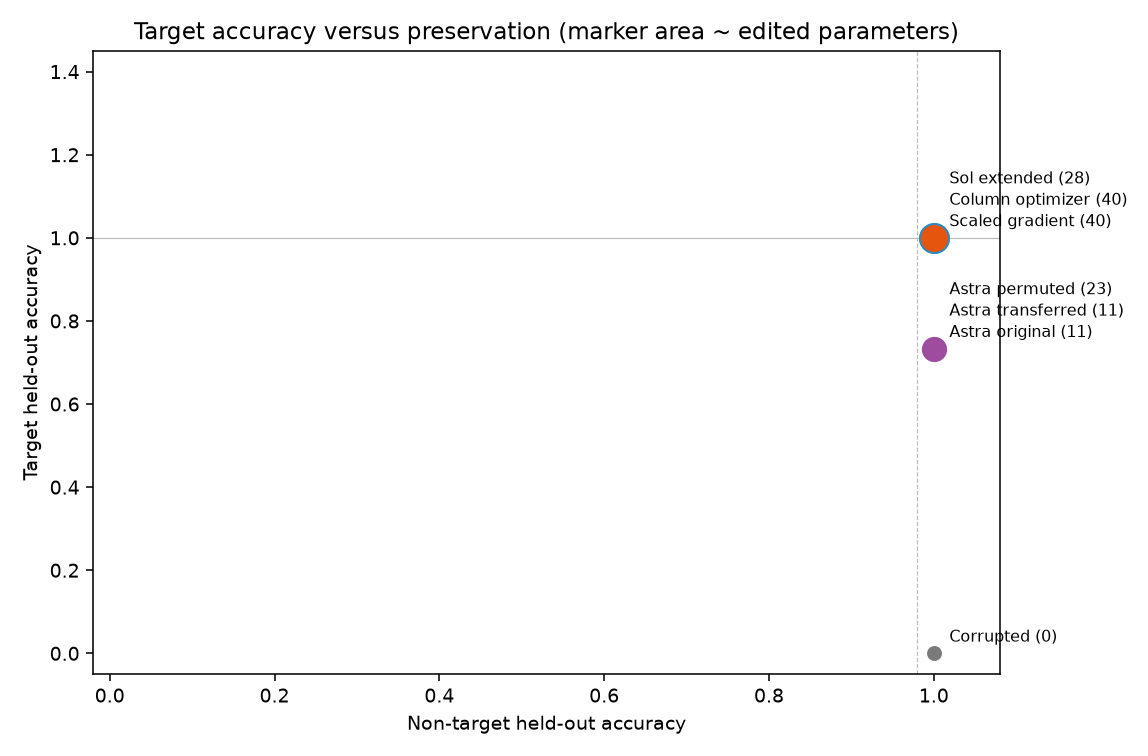

,call_id,model,output_tokens,reasoning_tokens,actual_cost_usd,cumulative_usd
0,one_shot-gpt-6.2-sol,gpt-6.2-sol,6000,6000,0.107342,0.107342
1,one_shot-gpt-6.2-astra,gpt-6.2-astra,2010,1339,0.269768,0.377110
2,permuted-one-shot-gpt-6.2-astra,gpt-6.2-astra,3474,2704,0.328360,0.705470
3,extended-one-shot-gpt-6.2-sol,gpt-6.2-sol,7903,7017,0.081403,0.786873


In [7]:
import pandas as pd
from IPython.display import Image, display

comparison = pd.read_csv(ROOT / "results" / "followup" / "comparison.csv")
display(comparison)
display(Image(filename=str(ROOT / "results" / "figures" / "followup_comparison.png")))
ledger = pd.read_csv(ROOT / "results" / "api_usage.csv")
display(ledger[["call_id", "model", "output_tokens", "reasoning_tokens", "actual_cost_usd", "cumulative_usd"]])
